In [25]:
import pandas as pd
import numpy as np


In [26]:
aqi_data=pd.read_csv("AirQualityUCI.csv",sep=";",decimal=",")

In [27]:
aqi_data.tail()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
9466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9467,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9469,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9470,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
aqi_data.loc[[9356,9357,9358,9359]]

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
9356,04/04/2005,14.00.00,2.2,1071.0,-200.0,11.9,1047.0,265.0,654.0,168.0,1129.0,816.0,28.5,13.1,0.5028,NaN,NaN
9357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9358,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9359,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
aqi_data=aqi_data.iloc[:9357,:-2] ## dont run this code again beecause it will delete the last 2 columns and the last 4 rows

In [30]:
aqi_data.tail()  #so there are 9357 rows and 15 columns in the dataset

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
9352,04/04/2005,10.00.00,3.1,1314.0,-200.0,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568
9353,04/04/2005,11.00.00,2.4,1163.0,-200.0,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119
9354,04/04/2005,12.00.00,2.4,1142.0,-200.0,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406
9355,04/04/2005,13.00.00,2.1,1003.0,-200.0,9.5,961.0,235.0,702.0,156.0,1041.0,770.0,28.3,13.5,0.5139
9356,04/04/2005,14.00.00,2.2,1071.0,-200.0,11.9,1047.0,265.0,654.0,168.0,1129.0,816.0,28.5,13.1,0.5028


In [31]:
#checking for null values
aqi_data.isnull().sum()

Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64

In [32]:
#here missing values are represented as -200 in the dataset, so we will replace them with NaN
aqi_data.replace(-200,np.nan,inplace=True)

In [33]:
aqi_data.isnull().sum()  #now we can see the number of missing values in each column

Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64

In [34]:
#get the mean of each column except date and time
aqi_data.mean(numeric_only=True)
#filling missing values with mean of each column
aqi_data.fillna(aqi_data.mean(numeric_only=True),inplace=True) 

In [35]:
aqi_data.isnull().sum()  #now we can see the number of missing values in each column

Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64

**Two tasks can be performed on this dataset
1) forecasting 
2) regression**

In [36]:
"""The input to Prophet is always a dataframe with two columns: ds and y.
The ds (datestamp) column should be of a format expected by Pandas,
 ideally YYYY-MM-DD for a date or YYYY-MM-DD HH:MM:SS for a timestamp.
   The y column must be numeric, and represents the measurement we wish to forecast."""

#changing the format of date
aqi_data["Date"]=pd.to_datetime(aqi_data["Date"],format="%d/%m/%Y")
#changing the format of time
aqi_data["Time"]=pd.to_datetime(aqi_data["Time"],format="%H.%M.%S").dt.time
#now we will combine date and time into a single column
date_time=pd.concat([aqi_data["Date"],aqi_data["Time"]],axis=1)
date_time.head()

,Date,Time
0,2004-03-10,18:00:00
1,2004-03-10,19:00:00
2,2004-03-10,20:00:00
3,2004-03-10,21:00:00
4,2004-03-10,22:00:00


In [37]:
date_time.shape

(9357, 2)

In [38]:
date_time["ds"]=date_time["Date"].astype(str)+" "+date_time["Time"].astype(str)
date_time["ds"]=pd.to_datetime(date_time["ds"])
date_time.head()

,Date,Time,ds
0,2004-03-10,18:00:00,2004-03-10 18:00:00
1,2004-03-10,19:00:00,2004-03-10 19:00:00
2,2004-03-10,20:00:00,2004-03-10 20:00:00
3,2004-03-10,21:00:00,2004-03-10 21:00:00
4,2004-03-10,22:00:00,2004-03-10 22:00:00


In [39]:
data=pd.DataFrame()
data["ds"]=date_time["ds"]
data["y"]=aqi_data["RH"] #we will forecast relative humidity (RH) using Prophet
data.tail()

,ds,y
9352,2005-04-04 10:00:00,29.3
9353,2005-04-04 11:00:00,23.7
9354,2005-04-04 12:00:00,18.3
9355,2005-04-04 13:00:00,13.5
9356,2005-04-04 14:00:00,13.1


In [40]:
# %pip install prophet
from prophet import Prophet

In [41]:
#doin as per the documentation of prophet
model = Prophet()
model.fit(data)



00:33:00 - cmdstanpy - INFO - Chain [1] start processing
00:33:01 - cmdstanpy - INFO - Chain [1] done processing


In [42]:
future = model.make_future_dataframe(periods=365) #here we are predicting for 365 days in future with hourly frequency
future.tail()

,ds
9717,2006-03-31 14:00:00
9718,2006-04-01 14:00:00
9719,2006-04-02 14:00:00
9720,2006-04-03 14:00:00
9721,2006-04-04 14:00:00


In [43]:
forecast = model.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail() #here yhat is the predicted value of y, yhat_lower is the lower bound of the predicted value and yhat_upper is the upper bound of the predicted value
#what is lower bound and upper bound of the predicted value? it is the range of values in which the actual value is expected to fall with a certain confidence level. by default, prophet uses a confidence level of 95%, which means that there is a 95% chance that the actual value will fall within the range of yhat_lower and yhat_upper.

,ds,yhat,yhat_lower,yhat_upper
9717,2006-03-31 14:00:00,4.095539,-86.494488,99.564661
9718,2006-04-01 14:00:00,2.752197,-87.569122,97.840843
9719,2006-04-02 14:00:00,2.928545,-87.196522,95.749294
9720,2006-04-03 14:00:00,1.181969,-89.512452,94.676289
9721,2006-04-04 14:00:00,2.462583,-91.748960,98.894251


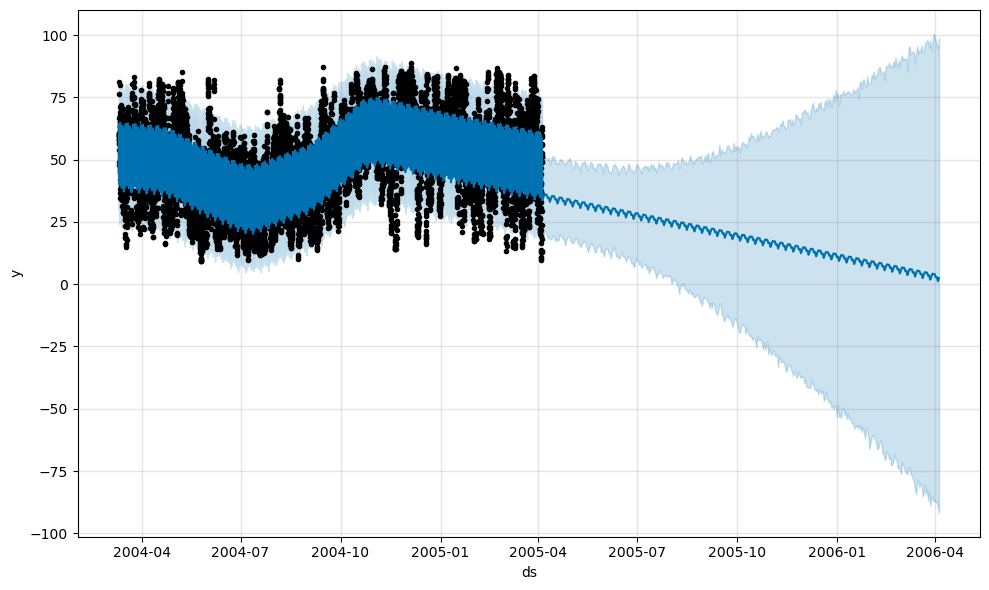

In [44]:
fig1 = model.plot(forecast)

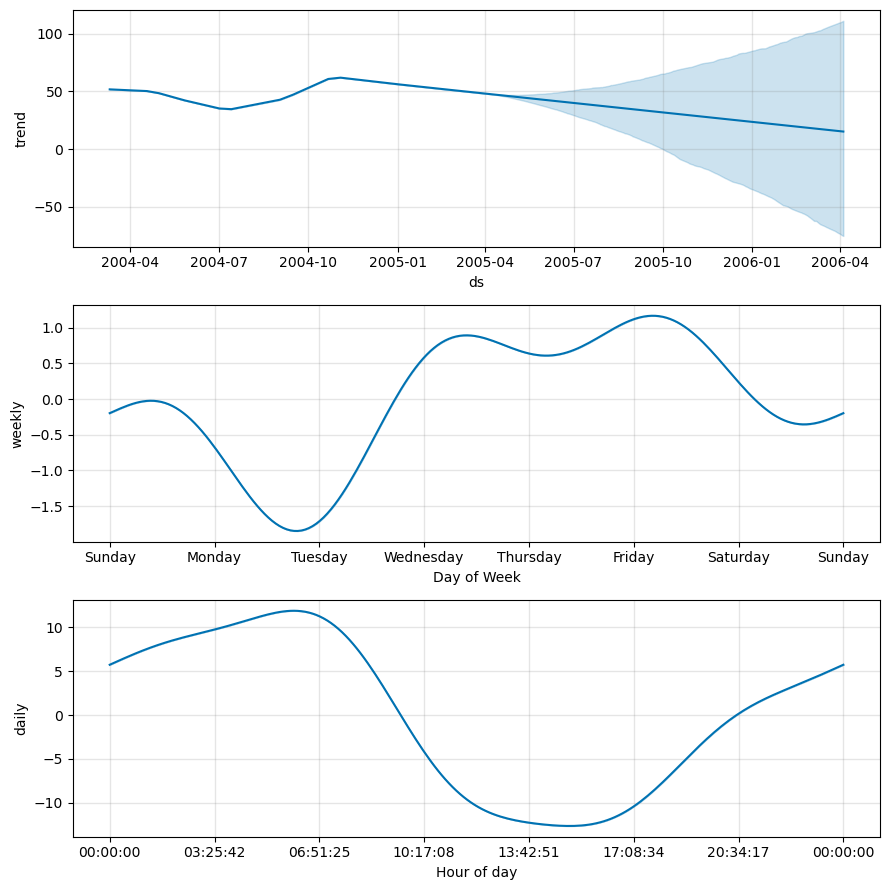

In [45]:
fig2 = model.plot_components(forecast)


## Forecasting Results

In this section, we have forecasted the relative humidity using Prophet time series forecasting model. The model captures temporal patterns and seasonality in the humidity data to provide predictions for future periods.

In [46]:
from prophet.plot import plot_plotly, plot_components_plotly

plot_plotly(model, forecast)

In [47]:
plot_components_plotly(model, forecast)

